Drift and retraining: how often must the model be retrained? Sources: `modeling/04_drift.py` (prediction test); `embedding/04_tags_trend.ipynb`, `05_drift.ipynb`, `11_watermark_check.py` (descriptive trends).

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load = lambda rel: json.loads((ROOT / rel).read_text())
show = lambda rel, width=720: display(Image(filename=str(ROOT / rel), width=width))
pd.set_option("display.precision", 3)

Prediction test: fixed test year, 2-year training windows of 5,000 serials; only the window's age changes.

In [2]:
d = load("modeling/out/drift_auc.json")
rows = []
for feat, name in [("S", "tags and structure"), ("T", "chapter text")]:
    for ty, gaps in d[feat].items():
        if ty.isdigit():
            for gap, v in gaps.items():
                rows.append({"features": name, "test year": int(ty), "years older": int(gap), "AUC": v["auc"]})
tab = pd.DataFrame(rows).pivot_table(index=["features", "test year"], columns="years older", values="AUC")
print(f"AUC change per extra year of training-data age: tags {d['S']['auc_change_per_year_of_gap']:+.3f}, text {d['T']['auc_change_per_year_of_gap']:+.3f}")
tab

AUC change per extra year of training-data age: tags -0.026, text -0.008


years older                       1      2      3      4      5
features           test year                                   
chapter text       2020       0.837  0.825    NaN    NaN    NaN
                   2021       0.836  0.830  0.822    NaN    NaN
                   2022       0.841  0.831  0.819  0.811    NaN
                   2023       0.835  0.832  0.825  0.817  0.805
tags and structure 2020       0.762  0.728    NaN    NaN    NaN
                   2021       0.790  0.733  0.729    NaN    NaN
                   2022       0.814  0.806  0.754  0.731    NaN
                   2023       0.813  0.807  0.794  0.761  0.723

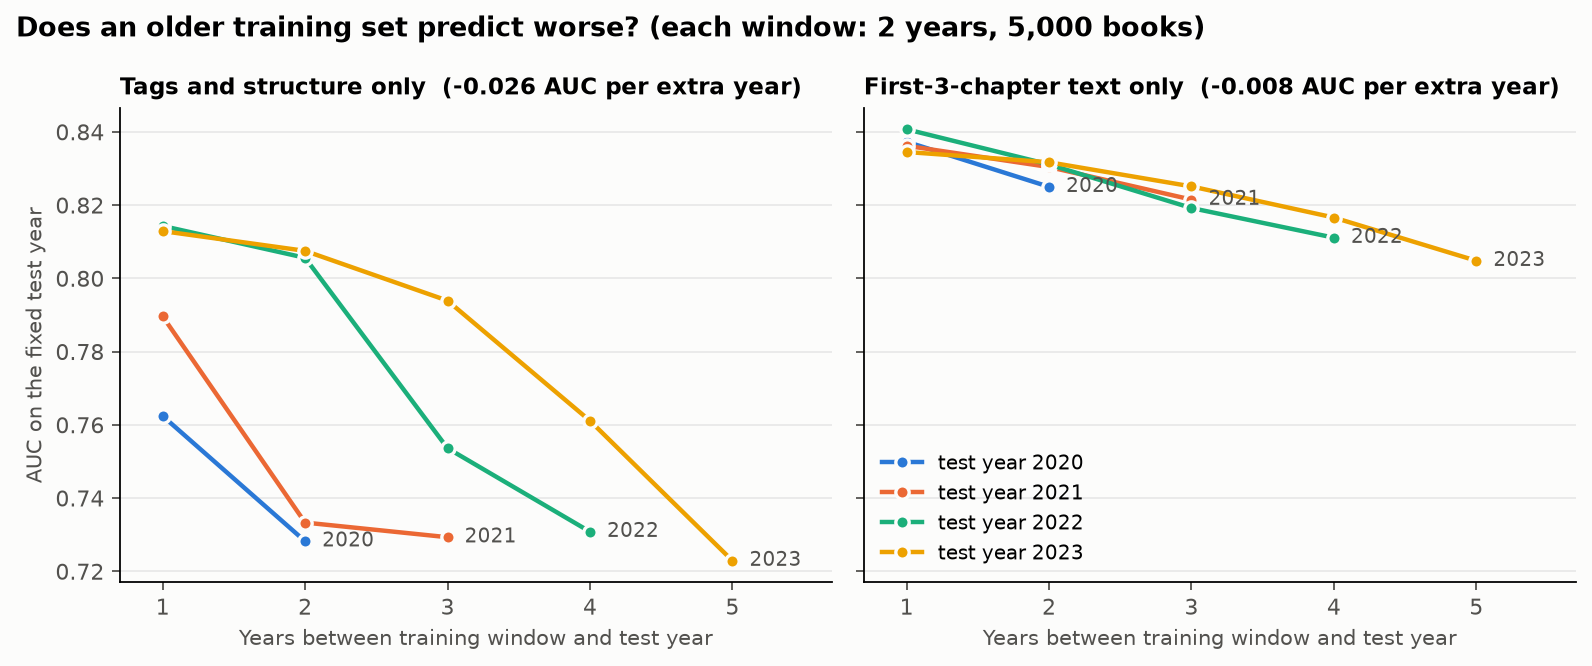

In [3]:
show("modeling/out/figs/drift_auc.png")

For tags the loss is mostly a step: windows that end before 2020 score clearly worse (test year 2022: 0.806 with 2019–20 data, 0.754 with 2018–19). That is when tag usage changed (Progression went from 8% to 34% of new serials between 2020 and 2021). The text model declines smoothly and slowly.

What wins within a cohort. Tags: rank correlation of each tag's lift between years (40 tags present since 2017). Text: cosine similarity of the "top 10% minus others" direction in the 1,536-d embedding, corrected for sampling noise, watermarks removed.

In [4]:
ts = load("embedding/out/tags_summary.json")
wn = load("embedding/out/watermark_check.json")["no_watermark"]
pd.DataFrame({"tags: lift rank correlation": ts["lift_corr_by_gap_clean"], "text: preference direction similarity": wn["dir_by_gap_disatt"]}).rename_axis("years apart")

,tags: lift rank correlation,text: preference direction similarity
years apart,,
1,0.879,0.997
2,0.871,0.971
3,0.841,0.968
4,0.796,0.951
5,0.719,0.941
6,0.690,0.928
7,0.620,0.918
8,NaN,0.935


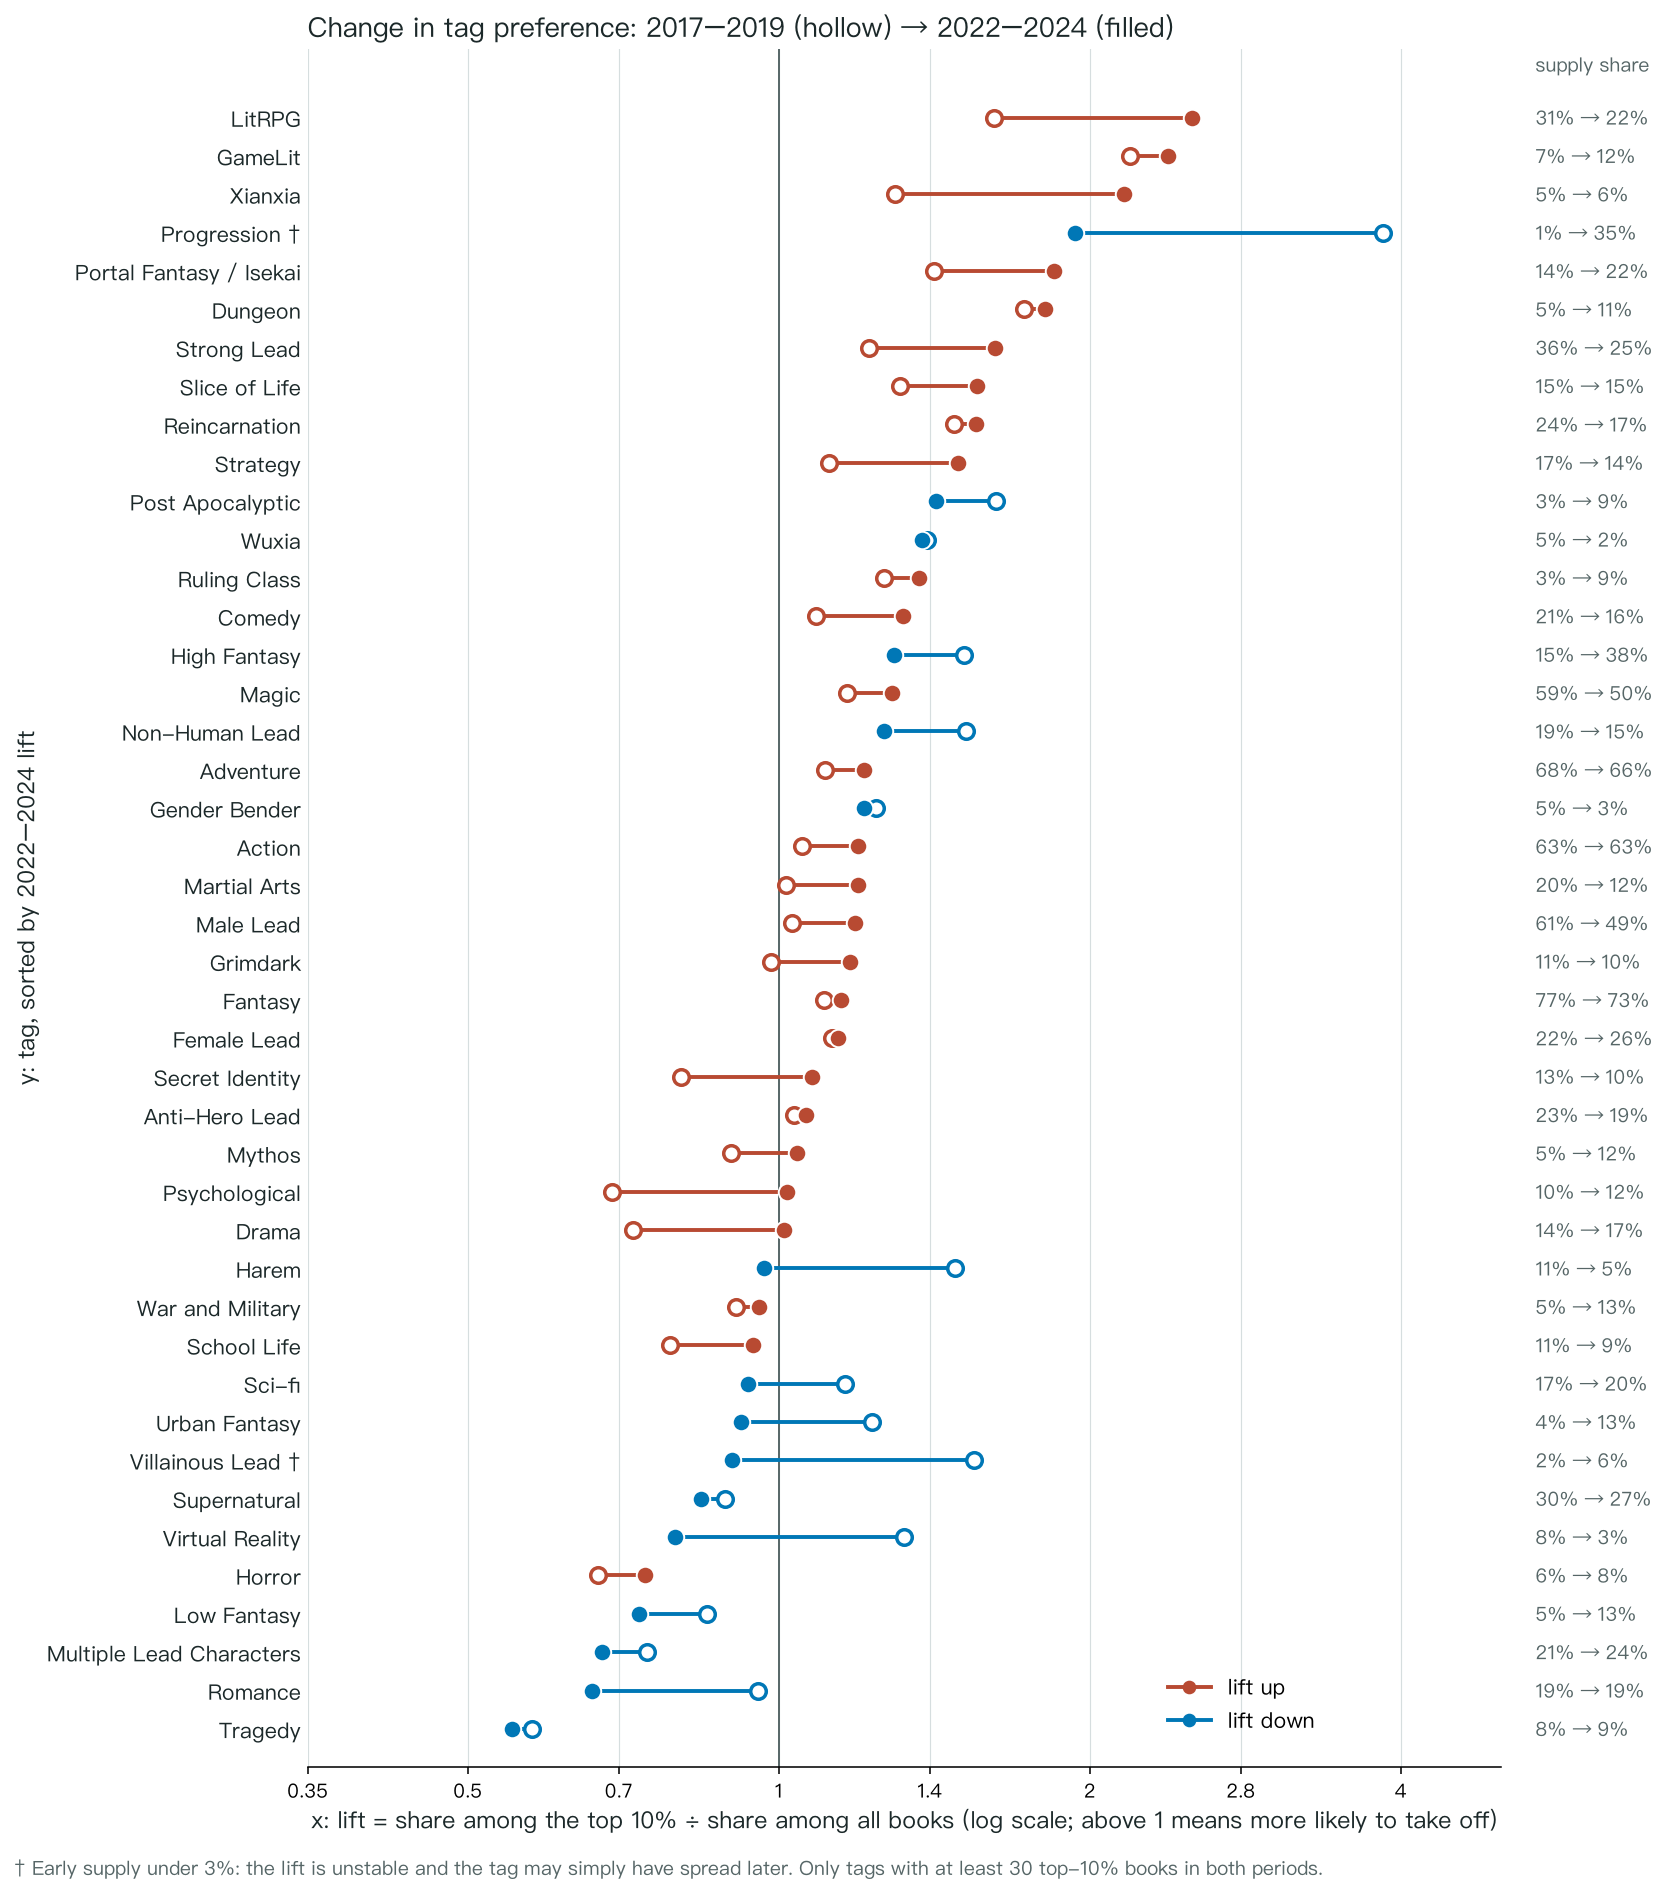

In [5]:
show("embedding/out/figs/tags_compare.png")

Takeaways: a model built on tags goes stale quickly, especially when the platform's tag usage changes; a model built on the story ages slowly. Retrain at least once a year and rely mainly on the text. Within each cohort, what wins looks similar across years (0.94 eight years apart) while the market drifts and hits move with it (cosine 0.90). All labels are measured in 2025, so cohorts share later readers; this stability may be overstated, and a deployed model probably decays faster than measured here.